<a href="https://colab.research.google.com/github/amansingh4847/NLP/blob/main/unit2/Topic%20Modeling%20using%20Latent%20Semantic%20Analysis%20(LSA).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


TOPIC MODELING USING LATENT SEMANTIC ANALYSIS


Topic 1:
learning, machine, technology, intelligence, artificial, transforming, software, programming, applications, data

Topic 2:
popular, cricket, football, games, india, sport, played, world, millions, attract

Topic 3:
software, using, process, information, hardware, coding, development, debugging, requires, testing

DOCUMENT TOPIC ASSIGNMENTS

                                                                Document Dominant Topic  Topic Score
Machine learning and artificial intelligence are transforming technology        Topic 1        0.736
         Deep learning uses neural networks for intelligent applications        Topic 1        0.329
                   Python programming is widely used in machine learning        Topic 1        0.515
          Artificial intelligence helps computers solve complex problems        Topic 1        0.406
     Data science involves data analysis and machine learning techniques        Topic 1       

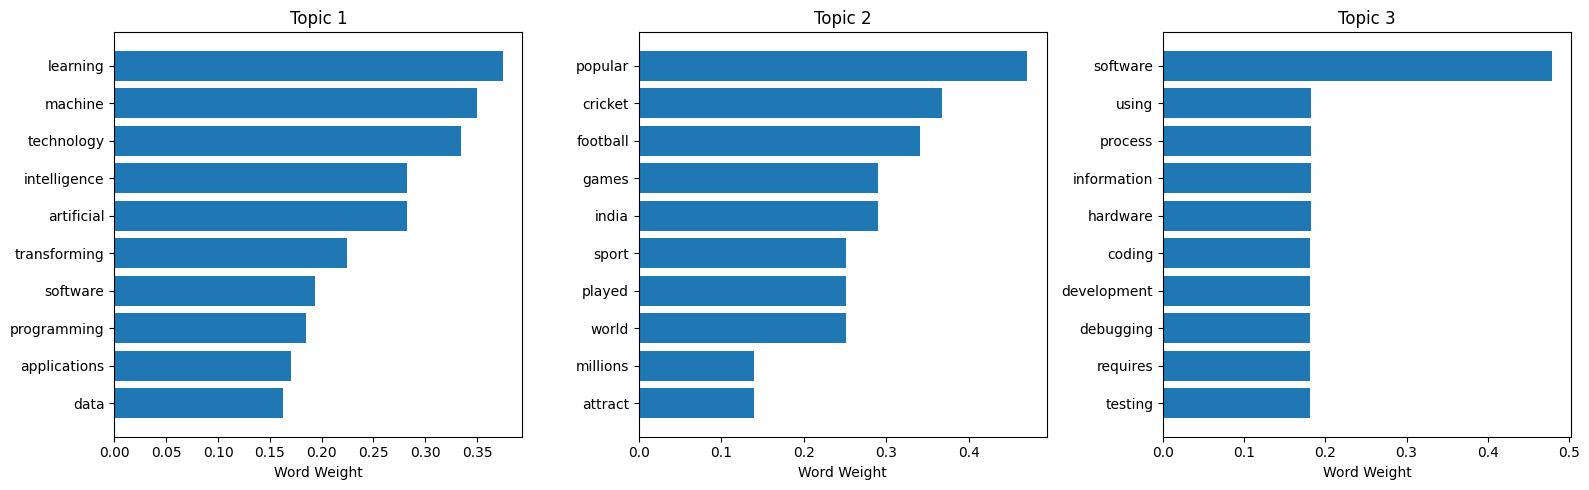

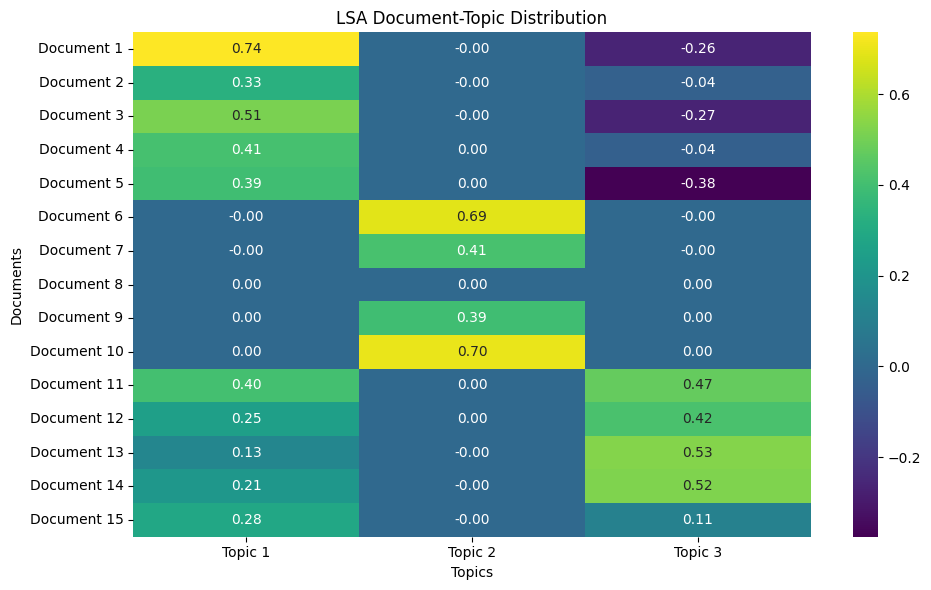


EXPLAINED VARIANCE RATIO
Topic 1: 0.0521
Topic 2: 0.0710
Topic 3: 0.0863

Total explained variance: 20.94 %

LSA Topic Modeling Completed Successfully!


In [6]:

# Topic Modeling using Latent Semantic Analysis (LSA)

!pip install -q scikit-learn nltk matplotlib pandas seaborn

import nltk
nltk.download('stopwords', quiet=True)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

# Sample documents
documents = [
    "Machine learning and artificial intelligence are transforming technology",
    "Deep learning uses neural networks for intelligent applications",
    "Python programming is widely used in machine learning",
    "Artificial intelligence helps computers solve complex problems",
    "Data science involves data analysis and machine learning techniques",
    "Football is a popular sport played around the world",
    "Cricket players practice batting bowling and fielding",
    "Sports improve physical fitness and teamwork",
    "Football tournaments attract millions of fans",
    "Cricket is one of the most popular games in India",
    "Technology companies develop software and computer applications",
    "Programming languages help developers build software",
    "Software development requires coding testing and debugging",
    "Computers process information using hardware and software",
    "Technology is changing education and business"
]

# Text preprocessing
stop_words = set(stopwords.words('english'))

def preprocess(text):
    words = text.lower().split()
    return " ".join([
        word for word in words
        if word.isalpha() and word not in stop_words
    ])

cleaned_documents = [preprocess(doc) for doc in documents]

# Convert text into TF-IDF matrix
vectorizer = TfidfVectorizer(
    max_df=0.95,
    min_df=1,
    stop_words='english'
)

tfidf_matrix = vectorizer.fit_transform(cleaned_documents)

# Apply Latent Semantic Analysis using Truncated SVD
num_topics = 3

lsa_model = TruncatedSVD(
    n_components=num_topics,
    random_state=42,
    n_iter=10
)

document_topic_matrix = lsa_model.fit_transform(tfidf_matrix)

# Extract topic keywords
feature_names = vectorizer.get_feature_names_out()

print("\nTOPIC MODELING USING LATENT SEMANTIC ANALYSIS\n")

for topic_index, topic in enumerate(lsa_model.components_):
    top_words = [
        feature_names[i]
        for i in topic.argsort()[-10:][::-1]
    ]

    print(f"\nTopic {topic_index + 1}:")
    print(", ".join(top_words))

# Assign dominant topics to documents
results = []

for i, topic_values in enumerate(document_topic_matrix):
    dominant_topic = topic_values.argmax()

    results.append({
        'Document': documents[i],
        'Dominant Topic': f"Topic {dominant_topic + 1}",
        'Topic Score': round(topic_values[dominant_topic], 3)
    })

df = pd.DataFrame(results)

print("\nDOCUMENT TOPIC ASSIGNMENTS\n")
print(df.to_string(index=False))

# Visualize topic-word distribution
fig, axes = plt.subplots(1, num_topics, figsize=(16, 5))

for i, ax in enumerate(axes):
    top_indices = lsa_model.components_[i].argsort()[-10:][::-1]

    words = feature_names[top_indices]
    weights = lsa_model.components_[i][top_indices]

    ax.barh(words[::-1], weights[::-1])
    ax.set_title(f"Topic {i + 1}")
    ax.set_xlabel("Word Weight")

plt.tight_layout()
plt.show()

# Visualize document-topic matrix
plt.figure(figsize=(10, 6))

sns.heatmap(
    document_topic_matrix,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    xticklabels=[f"Topic {i+1}" for i in range(num_topics)],
    yticklabels=[f"Document {i+1}" for i in range(len(documents))]
)

plt.title("LSA Document-Topic Distribution")
plt.xlabel("Topics")
plt.ylabel("Documents")
plt.tight_layout()
plt.show()

# Display explained variance
print("\nEXPLAINED VARIANCE RATIO")
for i, variance in enumerate(lsa_model.explained_variance_ratio_):
    print(f"Topic {i+1}: {variance:.4f}")

print(
    "\nTotal explained variance:",
    round(lsa_model.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

print("\nLSA Topic Modeling Completed Successfully!")
